In [1]:
import xarray as xr
import math
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.util as cutil

In [2]:
%cd /home/michele/DATA/ISCA_input/
!ls

/archive/michele/data/ISCA_input
ami_qflux_ctrl_ice_4320_mod.nc
ami_qflux_ctrl_ice_4320.nc
flux_lhe_anom_20_70,80.nc
flux_lhe_anom_2_70,80.nc
flux_lhe_anom_8e-07_30.nc
flux_lhe_anom.nc
grid.txt
ocean_qflux_anom_10_67,72.nc
ocean_qflux_anom_10_72,90.nc
ocean_qflux_anom_10_75,80.nc
ocean_qflux_anom_20_70,80.nc
ocean_qflux_anom_30_72,90.nc
ocean_qflux_anom_5_72,90.nc
ocean_qflux_anom_5_75,90.nc
siconc_clim_amip.nc
siconc_n13,64_s8,-65_PM2_fadN14_fadS10.nc
siconc_n13,64_s8,-65_PM2_fadN14_fadS10_sethalo.nc
siconc_n13,69_s8,-65_PM2_fadN14_fadS10.nc
siconc_N864S565_M2_N282S253_Nf14Sf10.nc
siconc_N869S565_M2_N252S253_Nf14Sf10.nc


In [3]:
ds = xr.open_dataset("ami_qflux_ctrl_ice_4320_mod.nc",decode_times=False)
latent_heat_anom = ds["ami_qflux_ctrl_ice_4320"].mean('time')
latent_heat_anom.name = 'ocean_qflux'
ds = latent_heat_anom.to_dataset()

In [4]:
ds.assign_attrs(
    units="W/m^2", description="Latent Heat Flux"
)

<xarray.Dataset>
Dimensions:      (lon: 256, lat: 128)
Coordinates:
  * lon          (lon) float64 0.0 1.406 2.812 4.219 ... 354.4 355.8 357.2 358.6
  * lat          (lat) float64 -88.93 -87.54 -86.14 -84.74 ... 86.14 87.54 88.93
Data variables:
    ocean_qflux  (lat, lon) float32 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
Attributes:
    units:        W/m^2
    description:  Latent Heat Flux

In [5]:
def Area(boolarr,lats=[-90,90],grid=1.):
  #This method calculate the area of a portion of a matrix in km^2. 
  #The portion of the matrix is given as a boolean array which is True 
  #where the area has to be calculated.
  #lons and lats lists define the boundaries of the original array
  #grid defines the dimension of a grid point.
  #! note that the array isn't (lon,lat) but (lat,lon) instead
  area = 0
  circearth = 40075
  for ilon in range(len(boolarr[0,:])):
    for jlat in range(len(boolarr[:,0])):
      if boolarr[jlat,ilon] == True:
        area += np.cos(np.deg2rad(lats[0] + jlat*grid))*(grid*circearth/360)**2
        
  return area

In [6]:
def Gaussian(x, a, b, c):
    return a * np.exp(-(x - b)**2 / (2 * c**2))

In [7]:
#latent heat of evaporation (J/kg) 
#need to convert the value.
#lhev = 2.5e6
#PARAMETERS:
lat_ext = 30
lat_1 = 72
lat_2 = 90
intensity = 30 #units: W/m^2

#initialize GAUSSIAN
latent_heat_anom.values = np.zeros(latent_heat_anom.shape)
#simple implementation: uniform polar flux
#latent_heat_anom.loc[90-lat_ext:,:] = intensity
#more complex: Gaussian heat
for i in range(lat_ext):
    latent_heat_anom.loc[90-0.5-i,:] = gaussian(90-i,intensity,90,lat_ext/2)

In [8]:
#initialize CIRCLE
latent_heat_anom.values = np.zeros(latent_heat_anom.shape)
latent_heat_anom.loc[lat_1:lat_2,:] = intensity
latent_heat_anom.loc[-lat_2:-lat_1,:] = intensity

In [9]:
#AREA computation
#hemisphere Area
hem_area = 259272096.7576036
'''
boolarr = latent_heat_anom
boolarr.values = np.zeros(latent_heat_anom.shape)
boolarr.loc[0:,:] = 1
hem_area = Area(boolarr.values,grid=1.4)
'''
print(hem_area)

#global area
global_area = 508841902.1820698
print(global_area)

#anomaly Area
boolarr = xr.where(latent_heat_anom>0,1,0)
anom_area = Area(boolarr.values,grid=1.4)
print(anom_area)

259272096.7576036
508841902.1820698
26565868.877979368


In [10]:
#subtract heating from nhem in order to have no overall atmospheric heating and retain the ITCZ position.
cooling = (anom_area/global_area)*intensity
#cooling = (anom_area/global_area)*intensity
latent_heat_anom.loc[:,:] -= cooling
print(cooling)
print(latent_heat_anom)

1.5662547893986398
<xarray.DataArray 'ocean_qflux' (lat: 128, lon: 256)>
array([[28.43374521, 28.43374521, 28.43374521, ..., 28.43374521,
        28.43374521, 28.43374521],
       [28.43374521, 28.43374521, 28.43374521, ..., 28.43374521,
        28.43374521, 28.43374521],
       [28.43374521, 28.43374521, 28.43374521, ..., 28.43374521,
        28.43374521, 28.43374521],
       ...,
       [28.43374521, 28.43374521, 28.43374521, ..., 28.43374521,
        28.43374521, 28.43374521],
       [28.43374521, 28.43374521, 28.43374521, ..., 28.43374521,
        28.43374521, 28.43374521],
       [28.43374521, 28.43374521, 28.43374521, ..., 28.43374521,
        28.43374521, 28.43374521]])
Coordinates:
  * lon      (lon) float64 0.0 1.406 2.812 4.219 ... 354.4 355.8 357.2 358.6
  * lat      (lat) float64 -88.93 -87.54 -86.14 -84.74 ... 86.14 87.54 88.93


In [11]:
#test
print(np.sum(latent_heat_anom,axis=(0,1)))

<xarray.DataArray 'ocean_qflux' ()>
array(148356.96306099)


In [12]:
#total intensity
print(anom_area*intensity)
#131820022
# 79870966
#132829344

796976066.339381


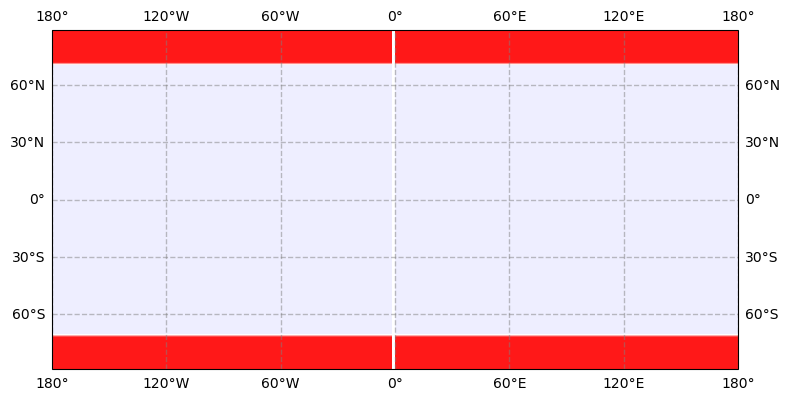

In [15]:
lon = ds['lon']
lat = ds['lat']

#multiple plots for having both contours and heatmap
mapcrs = ccrs.PlateCarree()
datacrs = ccrs.PlateCarree()
plt.figure(figsize=(8,5))
ax = plt.subplot(111, projection=mapcrs)
#ax.set_extent(extent, datacrs)
#ax.coastlines(linewidth = 0.5)

gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=1, color='gray', alpha=0.5, linestyle='--')
#plot contour
cs = ax.contourf(lon,lat,latent_heat_anom[:,:],np.arange(-31,32,2),cmap="bwr",transform=datacrs) #first ploot (float)
#plt.colorbar(cs)
plt.tight_layout()

In [14]:
ds['ocean_qflux']=latent_heat_anom
ds.to_netcdf('ocean_qflux_anom_'+str(intensity)+'_'+str(lat_1)+','+str(lat_2)+'.nc')